In [1]:
# =================================================================
# THESIS DATA PREPROCESSING & CATEGORY VALIDATION
# Corresponds to Sections 1.1.1 - 1.1.4
# =================================================================

import pandas as pd
import importlib, utils

importlib.reload(utils)

# --- (1.1.2) DATA LOADING & NORMALIZATION ---

# 1. Load raw files (Ensure UTF-8 encoding as per 1.1.2)
abacus_raw = pd.read_csv("abacus_2905-2506.csv", encoding='utf-8')
nexus_raw  = pd.read_csv("nexus_2905-2506.csv", encoding='utf-8')
vortex_raw = pd.read_csv("vortex_2605-2506.csv", encoding='utf-8')

# 2. Normalize individual marketplaces
# Logic: Strip non-numeric price chars, convert EUR/GBP to USD at the ECB rate of the snapshot date
abacus = utils.clean_and_normalize(abacus_raw, "abacus")
nexus  = utils.clean_and_normalize(nexus_raw, "nexus")
vortex = utils.clean_and_normalize(vortex_raw, "vortex")

# 3. Merge into Master Dataset
master = pd.concat([abacus, nexus, vortex], ignore_index=True)

In [2]:
# 1. Deduplication Rate per Marketplace
# Note: Calculated based on the ProductId, Date, and Category rule
dedup_stats = []
for market in master['_marketplace'].unique():
    m_data = master[master['_marketplace'] == market]
    # We compare unique daily entries vs total entries
    unique_entries = m_data.drop_duplicates(subset=['ProductId', 'Date', 'ActualCategory'])
    removed = len(m_data) - len(unique_entries)
    dedup_stats.append({
        'Marketplace': market,
        'Original_Rows': len(m_data),
        'Clean_Rows': len(unique_entries),
        'To be Removed': removed,
        'Dedup_Rate (%)': round((removed / len(m_data)) * 100, 2) if len(m_data) > 0 else 0
    })
print("--- 1. Deduplication Stats ---")
display(pd.DataFrame(dedup_stats))

--- 1. Deduplication Stats ---


,Marketplace,Original_Rows,Clean_Rows,To be Removed,Dedup_Rate (%)
0,abacus,7161,5834,1327,18.53
1,nexus,9690,6307,3383,34.91
2,vortex,2319,1865,454,19.58


## 2. Apply Deduplication Strategy and Create Unique Master List
Ensures price changes are tracked within unique category/product/date clusters

**ONLY RUN ONCE**: Uncomment the following lines to deduplicate and save the master dataset       

In [3]:
#master = utils.deduplicate_master(master)
#master.to_csv("outputs/master_dataset.csv", index=False)

In [2]:
import importlib, utils
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import scipy.stats as stats
importlib.reload(utils)

# Set visual style for the thesis
plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

# 2. Read Master and Create Unique Master List
master = pd.read_csv("outputs/master_dataset.csv", encoding='utf-8')

In [ ]:
# --- Sensitivity Analysis: ProductId vs. StableKey identification method ---
# Prices are compared in the listing's own currency ('Price'), so that daily exchange-rate
# conversion of EUR listings is not mistaken for a price change.
from scipy.stats import wilcoxon, spearmanr

# Method A: ProductId-based volatility
volatile_pid = master.groupby('ProductId')['Price'].nunique() > 1
inv_pid = master[['ProductId','_marketplace','ActualCategory']].drop_duplicates().copy()
inv_pid['is_volatile'] = inv_pid['ProductId'].isin(volatile_pid[volatile_pid].index)
pct_pid = (inv_pid.groupby(['ActualCategory','_marketplace'])['is_volatile'].mean()*100).unstack()

# Method B: StableKey-based volatility (marketplace + vendor + title)
master['StableKey'] = (master['_marketplace'] + '::' +
                        master['Vendor'].astype(str).str.strip().str.lower() + '::' +
                        master['Title'].astype(str).str.strip().str.lower())
volatile_sk = master.groupby('StableKey')['Price'].nunique() > 1
inv_sk = master[['StableKey','_marketplace','ActualCategory']].drop_duplicates().copy()
inv_sk['is_volatile'] = inv_sk['StableKey'].isin(volatile_sk[volatile_sk].index)
pct_sk = (inv_sk.groupby(['ActualCategory','_marketplace'])['is_volatile'].mean()*100).unstack()

# Pair up matching cells and compare
paired = pd.DataFrame({'ProductId': pct_pid.stack(), 'StableKey': pct_sk.stack()}).dropna().reset_index()

print("--- Overall comparison (all category-market cells) ---")
rho, p_corr = spearmanr(paired['ProductId'], paired['StableKey'])
stat, p = wilcoxon(paired['ProductId'], paired['StableKey'])
print(f"Spearman correlation: rho={rho:.3f}, p={p_corr:.4f}")
print(f"Wilcoxon signed-rank: W={stat:.2f}, p={p:.4f}")

print("\n--- Per-market breakdown ---")
for market in ['abacus','nexus','vortex']:
    sub = paired[paired['_marketplace']==market]
    diff = sub['ProductId'] - sub['StableKey']
    if diff.abs().sum() == 0:
        print(f"{market}: identical on both methods")
        continue
    stat, p = wilcoxon(sub['ProductId'], sub['StableKey'])
    print(f"{market}: n={len(sub)}, mean diff={diff.mean():.2f}pts, W={stat:.2f}, p={p:.4f}")

--- Overall comparison (all category-market cells) ---
Spearman correlation: rho=0.953, p=0.0000
Wilcoxon signed-rank: W=10.00, p=0.0745

--- Per-market breakdown ---
abacus: n=10, mean diff=-0.06pts, W=3.00, p=1.0000
nexus: n=11, mean diff=1.39pts, W=2.00, p=0.0469
vortex: identical on both methods


In [3]:
# Creates pd with unique products
# Fixed order so that 'first observation' always picks the same row: a few products appear twice
# on their first day with different prices, and an unsorted or unstable sort would pick either one.
master['Date'] = pd.to_datetime(master['Date'])
master = master.sort_values(['Date', '_marketplace', 'ProductId', 'Price'], kind='mergesort').reset_index(drop=True)
unique_master = master.drop_duplicates(subset=['_marketplace', 'Vendor', 'Title'], keep='first')

print(f"Total processed records: {len(master)}")
print(f"Unique Products: {len(unique_master)}")

Total processed records: 14006
Unique Products: 1609


In [4]:
importlib.reload(utils)

n_legit, share_incl, share_excl = utils.crackedsw_sensitivity_check(unique_master)

Flagged as legit/dual-use: 45 of 266 crackedsw rows
malware/exploits share, inclusive: 47.42%
malware/exploits share, excluding flagged tooling: 48.79%


In [5]:
import importlib
import catValidation as val
importlib.reload(val)

# --- (1.1.4) CATEGORY VALIDATION ---
# Part A: Keyword Frequency & Wordclouds (Inner Coherence)

# Generate sorted keyword lists for each of the 11 unified categories
categories = unique_master['ActualCategory'].unique()
for cat in categories:
    val.generate_frequency_list(unique_master, category=cat, output_dir="outputs/validation/keywords")
    val.create_category_wordcloud(unique_master, category=cat, output_dir="outputs/validation/wordclouds")

# --- (1.1.4) VALIDATION: INTER-CODER RELIABILITY ---
# Part B: Cohen’s Kappa (κ) Validation

# 1. The 10% sample was drawn ONCE (random_state=42) and handed to the second coder.
#    Do not redraw it: any change in row order would select different products.
#    The coded sample is read back from the coder's file in the next cell.
#master_sample = unique_master[['ProductId','Title','ActualCategory']].sample(frac=0.10, random_state=42)
#master_sample.to_csv("outputs/master_sample_dataset.csv", index=False)

# 2. Export master dataset for subsequent analysis
#master_sample_for_ICR = master_sample[['ProductId', 'Title']]
#master_sample_for_ICR.to_csv("outputs/master_sample_dataset.csv", index=False)


In [6]:
from sklearn.metrics import cohen_kappa_score

# 3. Get ICR CSV
master_icr = pd.read_csv("inputs/master_ICR_dataset.csv")

# 4. Take exactly the products the second coder coded and attach the researcher's category.
#    Match on ProductId AND title: Nexus occasionally reuses a ProductId for a different product.
#    Titles are compared as lowercase letters/digits only, so encoding artefacts do not matter.
norm = lambda t: ''.join(ch for ch in str(t).lower() if ch.isascii() and ch.isalnum())
researcher = master[['ProductId', 'Title', 'ActualCategory']].copy()
researcher['t'] = researcher['Title'].map(norm)
researcher = researcher.drop_duplicates(['ProductId', 't'])[['ProductId', 't', 'ActualCategory']]
icr = master_icr.copy()
icr['t'] = icr['Title'].map(norm)
merged = icr.merge(researcher, on=['ProductId', 't'], how='left')
print(f"Items coded by second coder: {len(master_icr)} | matched to dataset: {merged['ActualCategory'].notna().sum()}")
merged = merged.dropna(subset=['ActualCategory'])

# 5. Run Cohen's Kappa on the properly aligned data
kappa_score = cohen_kappa_score(merged['ActualCategory'], merged['ICR_Category'])

print(f"==========================================")
print(f"ICR VALIDATION RESULT")
print(f"Cohen's Kappa: {kappa_score:.3f}")
print(f"Raw agreement: {(merged['ActualCategory']==merged['ICR_Category']).mean()*100:.1f}%")
print(f"==========================================")

# 6. Full 11x11 confusion matrix
categories = ['botnet', 'crackedsw/tools', 'guide/exploit', 'guide/money', 'guide/other',
              'hack4hire', 'hosting', 'malware/exploits', 'others', 'pid/cards', 'reputation']

conf_matrix = pd.crosstab(merged['ActualCategory'], merged['ICR_Category'])
conf_matrix = conf_matrix.reindex(index=categories, columns=categories, fill_value=0)

display(conf_matrix)

Items coded by second coder: 161 | matched to dataset: 161
ICR VALIDATION RESULT
Cohen's Kappa: 0.678
Raw agreement: 75.8%


ICR_Category,botnet,crackedsw/tools,guide/exploit,guide/money,guide/other,hack4hire,hosting,malware/exploits,others,pid/cards,reputation
ActualCategory,,,,,,,,,,,
botnet,0,0,0,0,0,0,0,3,0,0,0
crackedsw/tools,0,27,0,0,0,0,0,1,1,1,0
guide/exploit,0,0,3,0,0,1,0,0,1,0,0
guide/money,0,0,0,10,0,0,0,0,0,0,0
guide/other,0,1,3,0,10,0,0,0,6,0,0
hack4hire,0,0,0,0,0,4,0,1,0,0,0
hosting,0,0,0,0,0,0,2,0,0,0,0
malware/exploits,0,5,3,1,0,1,1,59,6,0,0
others,0,0,0,0,0,0,0,1,0,0,0


#### **RQ1: What is the structural composition of dark web marketplaces, and what role do they play in enabling CaaS?**
_Focus: Scale, concentration, and diversity of the environment._
- **Volume Metrics:** Total observations vs. unique product count (1,830).
- **Identity Summary:** Unique vendor counts, payment types, and currency distribution (normalized to USD). 
- **High-Level Value:** Global Min/Max/Mean price to set the baseline.
- **Listing Trend:** Daily active listing counts over time to show market stability.
- **Diversity & Concentration:**
    - **Shannon Entropy Index:** To measure how "diverse" the market is (e.g., Generalist vs. Specialist).
    - **HHI & Gini Coefficient:** To measure vendor inequality (Does a "Super-Vendor" control most of the supply?).
- **Growth Correlation:** Pearson/Spearman correlation between the number of vendors and listing counts per day.

In [7]:
# 1. Load Preprocessed Master
#master = pd.read_csv("outputs/master_dataset.csv")
#master['Date'] = pd.to_datetime(master['Date']).dt.date

# --- Basic Descriptive Statistics ---
print(f"Total Master Listings: {len(master)}")
print(f"Unique Product Corpus: {len(unique_master)}")
print(f"Total Unique Vendors: {unique_master['Vendor'].nunique()}")

Total Master Listings: 14006
Unique Product Corpus: 1609
Total Unique Vendors: 74


In [8]:
# 2. Payment, Currency, and Offer Distribution of Unique Offers
print("\n--- 2. Payment Distribution of Unique Offers VS ALL ---")
payment_dist_unique = unique_master.groupby(['_marketplace', 'PaymentType']).size().unstack(fill_value=0)
display(payment_dist_unique)

print("\n--- 2. Currency Distribution of Unique ---")
currency_dist_unique = unique_master.groupby(['_marketplace', 'Currency']).size().unstack(fill_value=0)
display(currency_dist_unique)




--- 2. Payment Distribution of Unique Offers VS ALL ---


PaymentType,Escrow,FE
_marketplace,,
abacus,539,1
nexus,895,2
vortex,172,0



--- 2. Currency Distribution of Unique ---


Currency,EUR,GBP,USD
_marketplace,,,
abacus,0,0,540
nexus,98,1,798
vortex,0,0,172


In [9]:
# 3. Global Price Stats (USD)
print("\n--- 4. Global Price Stats (Unique Products) ---")
display(unique_master['Price_USD'].describe().round(2))

# 4. Calculate descriptive price statistics per marketplace
print("\n--- 4. Calculate descriptive price statistics per marketplace (only unique) ---")
market_price_profile_unique = unique_master.groupby('_marketplace')['Price_USD'].agg([
    'mean',    # The arithmetic average
    'median',  # The middle value (more robust to outliers)
    'min',     # The cheapest available product
    'max',     # The most expensive listing
    'std'      # Standard Deviation (shows price variety/spread)
]).round(2)

market_price_profile_unique.columns = [
    'Mean Price (USD)', 
    'Median Price (USD)', 
    'Min Price', 
    'Max Price', 
    'Std. Deviation'
]

display(market_price_profile_unique)



--- 4. Global Price Stats (Unique Products) ---


count      1609.00
mean        411.97
std        7191.29
min           0.10
25%           4.89
50%          10.00
75%          40.00
max      250000.00
Name: Price_USD, dtype: float64


--- 4. Calculate descriptive price statistics per marketplace (only unique) ---


,Mean Price (USD),Median Price (USD),Min Price,Max Price,Std. Deviation
_marketplace,,,,,
abacus,43.58,10.07,1.0,1124.3,101.54
nexus,701.13,10.00,0.1,250000.0,9623.19
vortex,60.54,5.00,1.9,2000.0,207.68


In [10]:
# 7. Price Stats per Category (Global)
print("\n--- 5. Category Price Stats (Global/Unique) ---")
display(unique_master.groupby('ActualCategory')['Price_USD'].agg(['min', 'max', 'median', 'mean']).round(2))


--- 5. Category Price Stats (Global/Unique) ---


,min,max,median,mean
ActualCategory,,,,
botnet,1.99,250000.00,60.00,15848.45
crackedsw/tools,1.40,523.95,15.00,46.00
guide/exploit,1.00,120.00,4.50,11.44
guide/money,1.99,999.00,4.99,18.49
guide/other,1.00,349.00,5.00,14.92
hack4hire,3.99,4990.00,100.00,798.77
hosting,8.00,3500.00,35.00,239.63
malware/exploits,0.10,8000.00,15.00,92.47
others,1.00,40.00,4.80,7.90


In [11]:
# 5. Global Offer Volatility (Specific Numbers) — corrected rule (Step 2.2)
importlib.reload(utils)
flags = utils.price_change_flags(master)

print(f"Total Unique Products: {len(flags)}")
print(f"Products with Price Changes: {flags['changed'].sum()}")
print(f"Global Product Volatility: {flags['changed'].mean() * 100:.2f}%")
display((flags.groupby('_marketplace')['changed'].mean() * 100).round(2))


Total Unique Products: 1609
Products with Price Changes: 49
Global Product Volatility: 3.05%


_marketplace
abacus    0.19
nexus     5.35
vortex    0.00
Name: changed, dtype: float64

In [12]:
# 6. Product Counts (Market & Category)
import pandas as pd

print("\n--- Unique Product Distribution & Global Market Share ---")

# 1. Define the global total based on unique_master to fix the missing variable
global_total_unique = unique_master.shape[0] 

# 2. Unique product counts per category per market
prod_counts = unique_master.groupby(['_marketplace', 'ActualCategory']).size().unstack(level=0, fill_value=0)

# 3. Marketplace percentages (Category share within that market)
market_totals = prod_counts.sum()
prod_pcts_internal = (prod_counts / market_totals) * 100

# 4. GLOBAL unique products in category across the whole ecosystem
global_cat_counts = unique_master.groupby('ActualCategory').size()
global_cat_pcts = (global_cat_counts / global_total_unique) * 100

# 5. Create the Final Multi-Index Table
# We want: [Market] -> Count, %
frames = []
for market in prod_counts.columns:
    m_frame = pd.DataFrame({
        (market, 'Count'): prod_counts[market],
        (market, '% of Market'): prod_pcts_internal[market]
    })
    frames.append(m_frame)

# Add the Global Ecosystem Column
global_frame = pd.DataFrame({
    ('Global Ecosystem', 'Count'): global_cat_counts,
    ('Global Ecosystem', '% of Corpus'): global_cat_pcts
})
frames.append(global_frame)

# Concatenate all parts
final_table = pd.concat(frames, axis=1)

# 6. Add the "TOTAL" Row at the bottom
# For the Market columns: Total Count | % of the 1,830 Global Corpus
total_row = {}
for market in prod_counts.columns:
    total_row[(market, 'Count')] = market_totals[market]
    total_row[(market, '% of Market')] = round((market_totals[market] / global_total_unique) * 100, 2)

total_row[('Global Ecosystem', 'Count')] = global_total_unique
total_row[('Global Ecosystem', '% of Corpus')] = 100.0

final_table.loc['TOTAL corpus share'] = total_row

display(final_table.round(2))


--- Unique Product Distribution & Global Market Share ---


abacus             nexus             vortex              \
                    Count % of Market Count % of Market  Count % of Market   
ActualCategory                                                               
botnet                 10        1.85    18        2.01      6        3.49   
crackedsw/tools       159       29.44    90       10.03     17        9.88   
guide/exploit          32        5.93    69        7.69     12        6.98   
guide/money            52        9.63    65        7.25     17        9.88   
guide/other            41        7.59   101       11.26     11        6.40   
hack4hire               0        0.00    24        2.68      5        2.91   
hosting                 5        0.93    14        1.56      0        0.00   
malware/exploits      215       39.81   468       52.17     80       46.51   
others                  5        0.93     5        0.56      5        2.91   
pid/cards              19        3.52    35        3.90     19       11.05   
reputation              2        0.37     8        0.89      0        0.00   
TOTAL corpus share    540       33.56   897       55.75    172       10.69   

                   Global Ecosystem              
                              Count % of Corpus  
ActualCategory                                   
botnet                           34        2.11  
crackedsw/tools                 266       16.53  
guide/exploit                   113        7.02  
guide/money                     134        8.33  
guide/other                     153        9.51  
hack4hire                        29        1.80  
hosting                          19        1.18  
malware/exploits                763       47.42  
others                           15        0.93  
pid/cards                        73        4.54  
reputation                       10        0.62  
TOTAL corpus share             1609      100.00

_marketplace     abacus       nexus     vortex
Date                                          
2025-05-26          NaN         NaN  88.868608
2025-05-29    41.963566  698.174684  77.764727
2025-06-01    42.025709  799.865481  59.363795
2025-06-04    42.103763  373.956724  59.363795
2025-06-07    36.489587  171.573454  59.363795
2025-06-10    42.485420   70.485632  61.427485
2025-06-13    42.627907  126.693450  61.329702
2025-06-16    42.416440   94.473554  61.329702
2025-06-19    44.701626  112.762075  61.329702
2025-06-22    44.779797   85.247596  61.262663
2025-06-25    44.942358  185.502280  61.262663
2025-06-28    44.728120  237.316512  61.262663


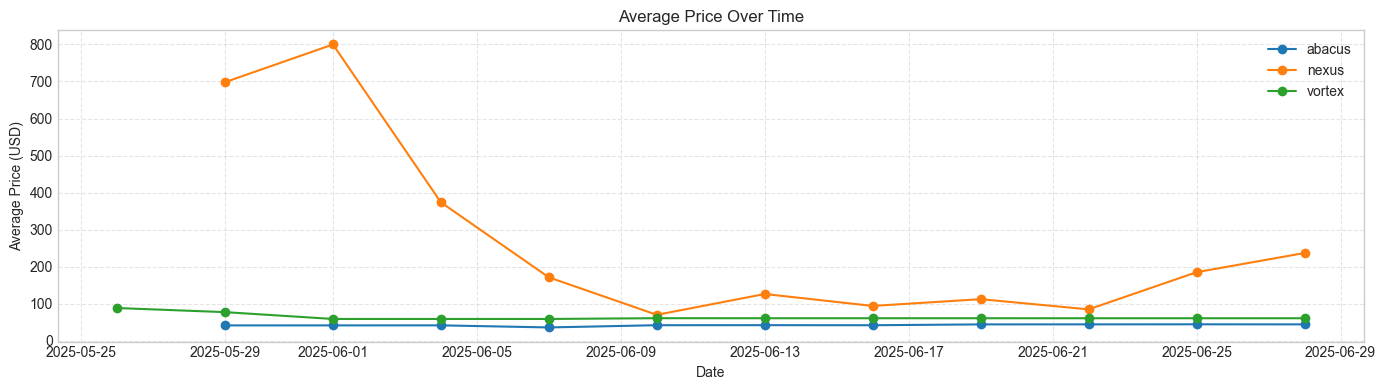

In [13]:
# 2. Compute average price over time per marketplace
daily_avg_price = master.groupby(['Date', '_marketplace'])['Price_USD'].mean().unstack()

print(daily_avg_price)

# 3. Create the plot matching the custom styling
plt.figure(figsize=(14, 4))
plt.plot(daily_avg_price, marker='o')

plt.title("Average Price Over Time")
plt.xlabel('Date')
plt.ylabel('Average Price (USD)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(daily_avg_price)
plt.tight_layout()

plt.show()

--- 7a. Daily Listing Volatility: Absolute Raw Data ---


_marketplace,abacus,nexus,vortex
Date,,,
2025-05-26,NaN,NaN,79.0
2025-05-29,558.0,675.0,110.0
2025-06-01,557.0,686.0,166.0
2025-06-04,558.0,671.0,166.0
2025-06-07,508.0,595.0,166.0
2025-06-10,559.0,583.0,167.0
2025-06-13,559.0,507.0,168.0
2025-06-16,559.0,486.0,168.0
2025-06-19,492.0,524.0,168.0


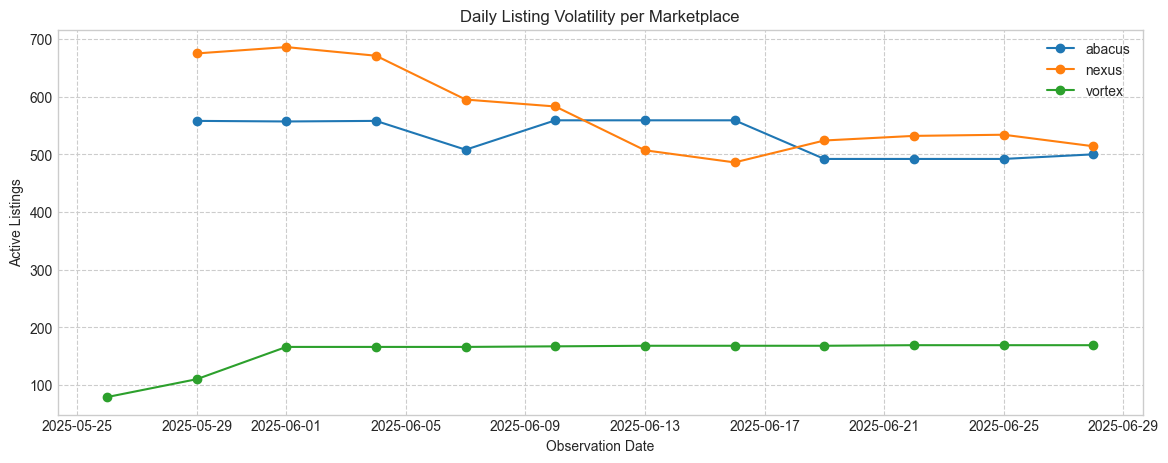

In [14]:
# 8. Daily Listing Volatility (Daily counts over time)

# 1. Create the daily counts table
# This is the "absolute data" source for the plot
daily_counts = master.groupby(['Date', '_marketplace']).size().unstack().sort_index()

print("--- 7a. Daily Listing Volatility: Absolute Raw Data ---")
display(daily_counts)

# 3. Render the Plot
plt.figure(figsize=(14,5))
plt.plot(daily_counts, marker='o')
plt.title("Daily Listing Volatility per Marketplace")
plt.ylabel("Active Listings")
plt.xlabel("Observation Date")
plt.grid(True, linestyle='--')
plt.legend(daily_counts)

plt.show()

In [15]:
# Market stability: Coefficient of Variation of daily listing counts (same counts as Figure 6)
# Dates on which a market was not collected are left out (no fill_value=0).
daily_counts = master.groupby(['Date', '_marketplace']).size().unstack().sort_index()

def get_cv(df):
    return (df.std() / df.mean() * 100).round(2)   # pandas skips missing dates per market

stability_comparison = pd.DataFrame({'Listing Count CV (%)': get_cv(daily_counts)})
vortex_from_june = daily_counts.loc[daily_counts.index >= pd.Timestamp('2025-06-01'), 'vortex']
stability_comparison.loc['vortex (from June 1)', 'Listing Count CV (%)'] = round(vortex_from_june.std() / vortex_from_june.mean() * 100, 2)

print("--- Marketplace Stability Comparison ---")
display(stability_comparison)


--- Marketplace Stability Comparison ---


,Listing Count CV (%)
_marketplace,
abacus,6.12
nexus,12.86
vortex,18.81
vortex (from June 1),0.75


In [16]:
# 9. Vendor-Listing Correlation Pearson Correlation Interpretation
print("\n--- Pearson Correlation (Vendors vs Listings) ---")
print(f"Meaning: As listing volume increases, the number of active vendors scales in almost direct proportion.")
daily_listings = master.groupby(['Date', '_marketplace']).size().unstack()
daily_vendors = master.groupby(['Date', '_marketplace'])['Vendor'].nunique().unstack()

for market in master['_marketplace'].unique():
    pair = pd.concat([daily_listings[market], daily_vendors[market]], axis=1).dropna()  # only dates the market was collected
    r, p = stats.pearsonr(pair.iloc[:, 0], pair.iloc[:, 1])
    interpretation = "Strong Positive" if r > 0.7 else "Moderate" if r > 0.4 else "Weak"
    print(f"[{market.upper()}] r = {r:.4f} (p = {p:.4f}) -> {interpretation} correlation.")



--- Pearson Correlation (Vendors vs Listings) ---
Meaning: As listing volume increases, the number of active vendors scales in almost direct proportion.
[VORTEX] r = 0.8715 (p = 0.0002) -> Strong Positive correlation.
[ABACUS] r = 0.7591 (p = 0.0067) -> Strong Positive correlation.
[NEXUS] r = 0.9049 (p = 0.0001) -> Strong Positive correlation.


In [17]:
# 10. Market Concentration (HHI)
hhi_results = {}
gini_results = {}
diversity_results = {}

for m in unique_master['_marketplace'].unique():
    m_df = unique_master[unique_master['_marketplace'] == m]
    vendor_listings = m_df.groupby('Vendor').size()
    
    hhi_results[m] = round(( (vendor_listings / vendor_listings.sum())**2 ).sum(), 4)
    gini_results[m] = round(utils.calculate_gini(vendor_listings), 3)
    diversity_results[m] = round(utils.calculate_shannon_entropy(m_df), 3)

# 2. Results Table
struct_table = pd.DataFrame({
    "HHI (Concentration)": hhi_results,
    "Gini (Inequality)": gini_results,
    "Shannon (Diversity)": diversity_results
})

print("--- Marketplace Structural Metrics for Unique Products ---")
display(struct_table)

--- Marketplace Structural Metrics for Unique Products ---


,HHI (Concentration),Gini (Inequality),Shannon (Diversity)
vortex,0.1383,0.589,1.741
abacus,0.1565,0.719,1.614
nexus,0.0514,0.598,1.641


#### **RQ2: What service categories dominate across Abacus, Nexus, and Vortex dark web marketplaces between May and June 2025?**
_Focus: Which services are professionalized and which are ephemeral?_
- **Volume Presence:** Daily active listing counts broken down by category    
- **Internal Domination:** Ranking the top categories _within_ each market to identify the internal leaders.
- **External Specialization (RMS):** Measuring which market over-indexes on a specific niche compared to the global norm.
- **Reliability (Volatility):** Calculating the Coefficient of Variation (CV) for category supply to separate professionalized infrastructure from "hit-and-run" services.
- **Temporal Stability:** **Chi-square test** to determine if the category composition changed significantly ($p < .05$) over the observation period.

In [18]:
# 4. Service Reliability: Coefficient of Variation (CV)
# From May 29 only: on May 26 only Vortex was collected, which would make every category look volatile
all_markets = master[pd.to_datetime(master['Date']) >= '2025-05-29']
cv_stats = utils.calculate_category_volatility(all_markets)

print("Stability Ranking (Lower is more reliable):")
print(cv_stats)

Stability Ranking (Lower is more reliable):
ActualCategory
hosting             0.031
pid/cards           0.031
crackedsw/tools     0.050
malware/exploits    0.060
guide/money         0.083
guide/exploit       0.088
others              0.088
botnet              0.154
reputation          0.190
guide/other         0.265
hack4hire           0.535
dtype: float64


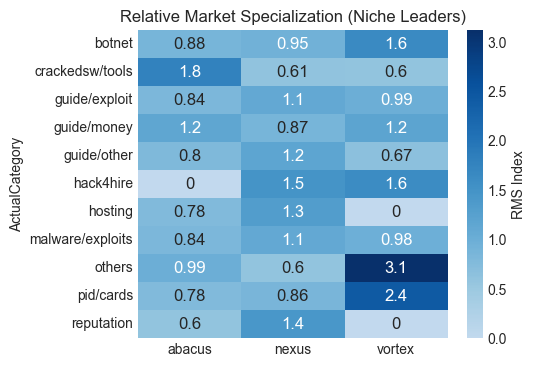

In [19]:
# 3. Relative Market Specialization (RMS)
rms_df = utils.calculate_rms_index(unique_master)
rms_df = rms_df[['abacus', 'nexus', 'vortex']].sort_index()   # fixed column order

plt.figure(figsize=(5, 4))
sns.heatmap(rms_df, annot=True, cmap="Blues", center=1.0, annot_kws={"size" : 12}, cbar_kws={'label': 'RMS Index'})
plt.title("Relative Market Specialization (Niche Leaders)")
plt.show()

#### Step 2.1 — How certain are the specialization indices?
Small categories often come from 1–3 vendors, so one vendor can make a market look "specialized". 
The vendor bootstrap resamples whole vendors within each market 2,000 times. An index counts as a real over-index only if its whole 95% interval lies above 1.0. 
The section table shows which category shares come from sections that were scraped on only one market.

In [20]:
importlib.reload(utils)

# RMS with 95% vendor-bootstrap intervals (takes ~1 min)
rms_ci = utils.rms_with_vendor_ci(unique_master)
rms_ci.to_csv('outputs/rms_with_ci.csv', index=False)
display(rms_ci[rms_ci['RMS'] > 1].sort_values(['Market', 'RMS'], ascending=[True, False]))

# Shannon diversity with 95% vendor-bootstrap intervals
display(utils.shannon_with_vendor_ci(unique_master))

# Sampling frame: unique listings per category within each scraped section
section_table = utils.composition_by_native_section(unique_master)
section_table.to_csv('outputs/composition_by_section.csv')
display(section_table)


,Category,Market,RMS,CI_low,CI_high,Listings,Vendors,Clearly_above_1,Clearly_below_1
4,crackedsw/tools,abacus,1.78,1.07,2.38,159,15,True,False
10,guide/money,abacus,1.16,0.05,2.07,52,4,False,False
16,hack4hire,nexus,1.48,0.94,2.19,24,10,False,False
29,reputation,nexus,1.44,0.89,2.00,8,6,False,False
18,hosting,nexus,1.32,0.49,2.05,14,5,False,False
14,guide/other,nexus,1.18,0.58,1.63,101,14,False,False
8,guide/exploit,nexus,1.10,0.70,1.50,69,19,False,False
21,malware/exploits,nexus,1.10,0.94,1.31,468,40,False,False
22,others,vortex,3.12,1.78,8.46,5,1,True,False
25,pid/cards,vortex,2.43,0.29,4.92,19,4,False,False


,H,CI_low,CI_high
abacus,1.614,1.081,1.842
nexus,1.641,1.353,1.817
vortex,1.741,1.264,1.881


ActualCategory                      botnet  crackedsw/tools  guide/exploit  \
_marketplace Category                                                        
abacus       BotnetMalware               8                6              9   
             ExploitKits                 0               33              0   
             Exploits                    0                5              2   
             Hosting                     0                0              2   
             SecuritySoftware            2              115             19   
nexus        HackingServices            13                4             31   
             HackingToolsEquipment       1               33             23   
             Hosting                     0                0              0   
             SoftwareMalware             4               53             15   
vortex       Exploits                    0                1              2   
             Hacking Software            0                0              0   
             HackingSoftware             0                8              2   
             Malware & Botnet            6                8              6   
             Services                    0                0              2   

ActualCategory                      guide/money  guide/other  hack4hire  \
_marketplace Category                                                     
abacus       BotnetMalware                    3            4          0   
             ExploitKits                      0            1          0   
             Exploits                         0            1          0   
             Hosting                          0            2          0   
             SecuritySoftware                49           33          0   
nexus        HackingServices                  5           13         22   
             HackingToolsEquipment            8           39          1   
             Hosting                          0            1          0   
             SoftwareMalware                 52           48          1   
vortex       Exploits                         0            2          0   
             Hacking Software                 1            0          0   
             HackingSoftware                  9            4          0   
             Malware & Botnet                 2            3          0   
             Services                         5            2          5   

ActualCategory                      hosting  malware/exploits  others  \
_marketplace Category                                                   
abacus       BotnetMalware                0               104       1   
             ExploitKits                  0                26       0   
             Exploits                     0                35       0   
             Hosting                      5                 2       0   
             SecuritySoftware             0                48       4   
nexus        HackingServices              1                54       3   
             HackingToolsEquipment        0               207       0   
             Hosting                     13                 3       0   
             SoftwareMalware              0               204       2   
vortex       Exploits                     0                 5       0   
             Hacking Software             0                 0       0   
             HackingSoftware              0                17       0   
             Malware & Botnet             0                51       0   
             Services                     0                 7       5   

ActualCategory                      pid/cards  reputation  
_marketplace Category                                      
abacus       BotnetMalware                  0           1  
             ExploitKits                    0           0  
             Exploits                       0           0  
             Hosting                       10           0  
             Security

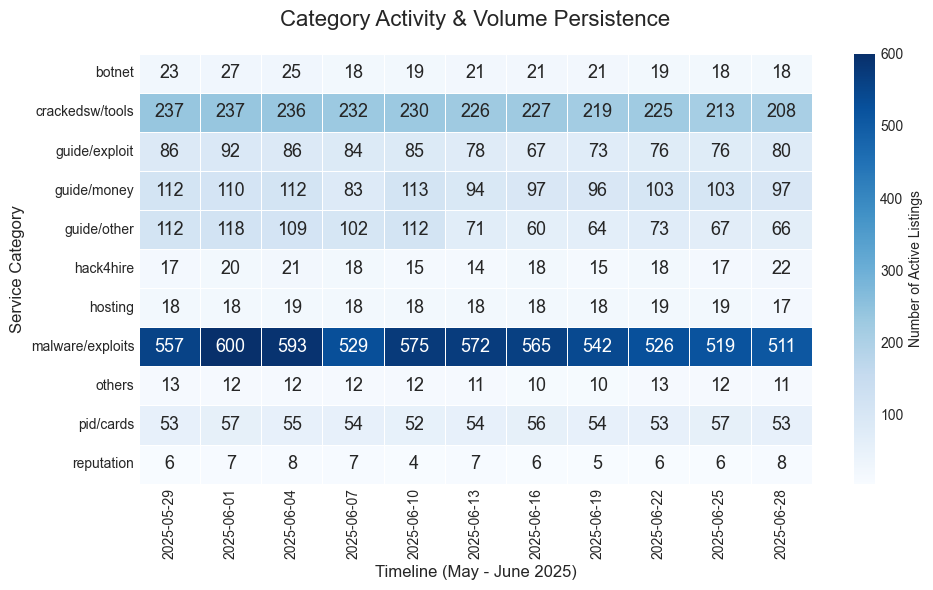

In [21]:
# Category Activity & Volume Persistence
master['StableKey'] = master['_marketplace'] + '::' + master['Vendor'].str.strip().str.lower() + '::' + master['Title'].str.strip().str.lower()
# From May 29 only (all three markets collected); May 26 contains Vortex alone
m29 = master[pd.to_datetime(master['Date']) >= '2025-05-29']
persistence_counts_master = m29.groupby(['ActualCategory', 'Date'])['StableKey'].nunique().unstack(fill_value=0)
persistence_counts_master.columns = pd.to_datetime(persistence_counts_master.columns).strftime('%Y-%m-%d')   # readable date labels

plt.figure(figsize=(10, 6))
sns.heatmap(persistence_counts_master, 
            cmap="Blues", 
            annot=True,
            fmt="d",
            annot_kws={"size" : 13},
            linewidths=.5,
            cbar_kws={'label': 'Number of Active Listings'})

plt.title("Category Activity & Volume Persistence", fontsize=16, pad=20)
plt.xlabel("Timeline (May - June 2025)", fontsize=12)
plt.ylabel("Service Category", fontsize=12)
plt.tight_layout()
plt.show()

In [22]:
# 5. Temporal Stability Test
stability_results = utils.run_composition_stability_test(unique_master)

print(f"--- Composition Stability Test ---")
print(f"Chi-Square Statistic: {stability_results['chi2']:.2f}")
print(f"Degrees of Freedom:   {stability_results['dof']}")
print(f"P-Value:              {stability_results['p_value']:.2e}")
print(f"Cramer's V:           {stability_results['cramers_v']:.3f}")
print(f"% cells with expected count < 5: {stability_results['pct_low_cells']:.1f}%")

if stability_results['p_value'] < 0.01:
    print("RESULT: Category composition changed SIGNIFICANTLY over time.")
else:
    print("RESULT: Category composition remained STABLE over time.")

--- Composition Stability Test ---
Chi-Square Statistic: 30.66
Degrees of Freedom:   10
P-Value:              6.68e-04
Cramer's V:           0.138
% cells with expected count < 5: 40.9%
RESULT: Category composition changed SIGNIFICANTLY over time.


### **RQ3: How are prices distributed, and do they differ significantly by category and market?**
_Focus: Pricing tiers and significant market differences._
- **Distribution:** Boxplots (log-scale) of prices for major categories to show medians and Interquartile Ranges (IQR).
- **Economic Tiers:** **Market Price Premium Index**—identifying if Nexus is a "Premium" market versus Abacus as a "Budget" market.
- **Significance:** **Kruskal-Wallis H-test** (followed by Dunn’s post-hoc) to prove if prices for the same category differ significantly between markets.
- **Individual Volatility:** Detecting the share of products that changed price at least once.

In [23]:
master = pd.read_csv("outputs/master_dataset.csv")

master['Date'] = pd.to_datetime(master['Date'])
master = master.sort_values(['Date', '_marketplace', 'ProductId', 'Price'], kind='mergesort').reset_index(drop=True)  # same fixed order as above
unique_master = master.drop_duplicates(subset=['_marketplace', 'Vendor', 'Title'], keep='first')

# 1. Descriptive Summary Table (N, Median, IQR) — thesis-ready format
price_summary = unique_master.groupby(['ActualCategory', '_marketplace'])['Price_USD'].agg(
    N='count',
    Median='median',
    IQR=lambda x: x.quantile(0.75) - x.quantile(0.25)
)
price_summary = price_summary.round(2)

# Pivot so each market gets its own N/Median/IQR column block, one row per category
table3 = price_summary.unstack(level='_marketplace')
table3 = table3.swaplevel(axis=1)

# Explicitly force column order — unstack() sorts alphabetically by default,
# which is why IQR was landing before Median regardless of the agg() order
markets = ['abacus', 'nexus', 'vortex']
stats = ['N', 'Median', 'IQR']
table3 = table3.reindex(columns=pd.MultiIndex.from_product([markets, stats]))

display(table3)

abacus                nexus                    vortex  \
                      N Median    IQR      N   Median       IQR      N   
ActualCategory                                                           
botnet             10.0  13.50  22.75   18.0  1250.00  31052.50    6.0   
crackedsw/tools   159.0  20.00  65.63   90.0    15.00     19.57   17.0   
guide/exploit      32.0   2.99   6.26   69.0     5.50      7.00   12.0   
guide/money        52.0   2.99   2.62   65.0     4.99      1.87   17.0   
guide/other        41.0   3.99  10.00  101.0     5.00      0.50   11.0   
hack4hire           NaN    NaN    NaN   24.0    75.00   1460.13    5.0   
hosting             5.0  20.00   9.99   14.0    78.00     70.00    NaN   
malware/exploits  215.0  15.00  50.50  468.0    17.50     37.11   80.0   
others              5.0   1.89   0.20    5.0     4.80     23.99    5.0   
pid/cards          19.0  11.02  16.51   35.0    25.00     33.67   19.0   
reputation          2.0   1.65   0.34    8.0    47.50     69.81    NaN   

                                 
                  Median    IQR  
ActualCategory                   
botnet              1.99   0.23  
crackedsw/tools     5.00  12.00  
guide/exploit       3.31   1.79  
guide/money         3.27   6.06  
guide/other         3.26   1.89  
hack4hire         100.00  50.00  
hosting              NaN    NaN  
malware/exploits    5.00  36.76  
others              5.50   0.00  
pid/cards          54.33   9.76  
reputation           NaN    NaN

In [24]:
# Prerequisite check: normality (Shapiro-Wilk) and variance homogeneity (Levene's)
# per category, justifying the use of non-parametric Kruskal-Wallis over ANOVA
from scipy.stats import shapiro, levene

normality_results = []
for cat in sorted(unique_master['ActualCategory'].unique()):
    cat_data = unique_master[unique_master['ActualCategory'] == cat]
    if len(cat_data) < 3:
        continue

    # Shapiro-Wilk: is the category's price distribution normal?
    sw_stat, sw_p = shapiro(cat_data['Price_USD'])

    # Levene's: is variance homogeneous across the markets within this category?
    groups = [g['Price_USD'].values for _, g in cat_data.groupby('_marketplace') if len(g) >= 2]
    if len(groups) >= 2:
        lev_stat, lev_p = levene(*groups)
    else:
        lev_stat, lev_p = None, None

    normality_results.append({
        'Category': cat,
        'Shapiro_W': round(sw_stat, 4),
        'Shapiro_p': f"{sw_p:.2e}" if sw_p < 0.001 else round(sw_p, 4),
        'Levene_W': round(lev_stat, 2) if lev_stat is not None else None,
        'Levene_p': round(lev_p, 4) if lev_p is not None else None
    })

normality_df = pd.DataFrame(normality_results)
print("--- Normality (Shapiro-Wilk) and Variance Homogeneity (Levene's) by Category ---")
display(normality_df)

n_non_normal = (normality_df['Shapiro_p'].apply(lambda x: float(x) < 0.05 if isinstance(x,(int,float)) else True)).sum()
n_heterogeneous = (normality_df['Levene_p'] < 0.05).sum()
print(f"\nCategories with non-normal price distribution (Shapiro-Wilk p<.05): {n_non_normal} of {len(normality_df)}")
print(f"Categories with heterogeneous variance across markets (Levene's p<.05): {n_heterogeneous} of {len(normality_df)}")

--- Normality (Shapiro-Wilk) and Variance Homogeneity (Levene's) by Category ---


,Category,Shapiro_W,Shapiro_p,Levene_W,Levene_p
0,botnet,0.3852,8.31e-11,1.73,0.1936
1,crackedsw/tools,0.5039,1.10e-26,1.31,0.2715
2,guide/exploit,0.4458,9.18e-19,0.80,0.4533
3,guide/money,0.1386,1.40e-24,3.21,0.0435
4,guide/other,0.3342,1.88e-23,4.53,0.0123
5,hack4hire,0.7093,2.87e-06,0.57,0.4578
6,hosting,0.2899,1.10e-08,0.43,0.5187
7,malware/exploits,0.1771,2.93e-49,1.43,0.2401
8,others,0.5662,1.27e-05,2.58,0.1172
9,pid/cards,0.2126,7.08e-18,0.94,0.3943



Categories with non-normal price distribution (Shapiro-Wilk p<.05): 11 of 11
Categories with heterogeneous variance across markets (Levene's p<.05): 2 of 11


In [25]:
# --- RQ3: Final Statistical Results Table (Kruskal-Wallis + Dunn's Post-hoc) ---

import pandas as pd
import scipy.stats as stats

results_list = []

for cat in unique_master['ActualCategory'].unique():
    cat_data = unique_master[unique_master['ActualCategory'] == cat]
    n_total = len(cat_data)
    k_markets = cat_data['_marketplace'].nunique()
    
    # We only run tests if the category exists in at least 2 markets
    if k_markets > 1:
        # 1. Run Kruskal-Wallis
        # We group the prices by marketplace
        groups = [group['Price_USD'].values for name, group in cat_data.groupby('_marketplace')]
        h_stat, p_val = stats.kruskal(*groups)
        
        # 2. Calculate Effect Size (Epsilon Squared)
        # Formula: epsilon_sq = h_stat / ((n_total**2 - 1) / (n_total + 1))
        epsilon_sq = h_stat / ((n_total**2 - 1) / (n_total + 1))
        
        # 3. Run Post-hoc Dunn's for Significant Pairs
        sig_pairs = utils.run_posthoc_dunn(cat_data)
        # Clean up the output string (e.g., "abacus vs nexus, nexus vs vortex")
        pairs_str = ", ".join([p.split(" (p=")[0] for p in sig_pairs]) if sig_pairs else "None"
        
        results_list.append({
            'Category': cat,
            'n_total': n_total,
            'H': round(h_stat, 2),
            'df': k_markets - 1,
            'p_value': f"{p_val:.2e}" if p_val < 0.001 else round(p_val, 4),
            'ε²': round(epsilon_sq, 3),
            'Significant Pairs': pairs_str
        })

# Create the final DataFrame
table_6_final = pd.DataFrame(results_list)
table_6_final = table_6_final.sort_values(by='Category', ascending=True)

print("--- Table 6: Kruskal–Wallis & Post-hoc Dunn Test Results ---")
display(table_6_final)

--- Table 6: Kruskal–Wallis & Post-hoc Dunn Test Results ---


,Category,n_total,H,df,p_value,ε²,Significant Pairs
8,botnet,34,20.93,2,2.85e-05,0.634,"abacus vs nexus, nexus vs vortex"
3,crackedsw/tools,266,15.55,2,4.21e-04,0.059,"abacus vs nexus, abacus vs vortex"
2,guide/exploit,113,7.50,2,0.0236,0.067,abacus vs nexus
1,guide/money,134,24.99,2,3.75e-06,0.188,abacus vs nexus
4,guide/other,153,12.35,2,0.0021,0.081,nexus vs vortex
0,hack4hire,29,0.01,1,0.9308,0.000,None
9,hosting,19,4.18,1,0.0409,0.232,abacus vs nexus
5,malware/exploits,763,14.74,2,6.30e-04,0.019,"abacus vs vortex, nexus vs vortex"
6,others,15,9.87,2,0.0072,0.705,"abacus vs nexus, abacus vs vortex"
7,pid/cards,73,16.84,2,2.20e-04,0.234,"abacus vs nexus, abacus vs vortex, nexus vs vo..."


#### Step 2.3 — Table 4 at vendor level
Listings from one vendor are not independent observations. The table below repeats the listing-level test (as above) and adds two vendor-level versions: Kruskal-Wallis on one median price per vendor per market (main result), and a cluster permutation test that shuffles market labels between whole vendor catalogues (robustness check).

In [26]:
importlib.reload(utils)

# Takes ~1 min because of the permutation test
table4_vendor = utils.kruskal_listing_and_vendor_level(unique_master)
table4_vendor.to_csv('outputs/table4_vendor_level.csv', index=False)
display(table4_vendor)


,Category,N listings,Vendors A/N/V,H (listings),p (listings),eps2 (listings),Pairs (listings),H (vendor medians),p (vendor medians),eps2 (vendor medians),Pairs (vendor medians),p (cluster permutation)
0,botnet,34,8/6/2,20.93,0.000029,0.634,"A-N, N-V",4.05,0.1320,0.270,None,0.0780
1,crackedsw/tools,266,15/19/7,15.55,0.000421,0.059,"A-N, A-V",0.64,0.7270,0.016,None,0.7701
2,guide/exploit,113,9/19/4,7.50,0.023600,0.067,A-N,0.80,0.6690,0.026,None,0.4498
3,guide/money,134,4/10/6,24.99,0.000004,0.188,A-N,0.65,0.7240,0.034,None,0.1904
4,guide/other,153,8/14/4,12.35,0.002080,0.081,N-V,3.00,0.2230,0.120,None,0.4563
5,hack4hire,29,0/10/3,0.01,0.931000,0.000,None,0.03,0.8650,0.002,None,0.9555
6,hosting,19,5/5/0,4.18,0.040900,0.232,A-N,3.96,0.0465,0.440,A-N,0.1174
7,malware/exploits,763,24/40/12,14.74,0.000630,0.019,"A-V, N-V",1.26,0.5340,0.017,None,0.7051
8,others,15,2/4/1,9.87,0.007190,0.705,"A-N, A-V",3.75,0.1530,0.625,None,0.1069
9,pid/cards,73,5/10/4,16.84,0.000220,0.234,All,4.22,0.1210,0.234,None,0.0715


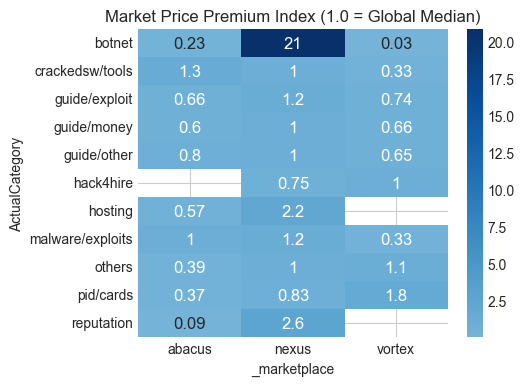

Index Interpretation: Values > 1.0 (Red) = Premium Pricing; Values < 1.0 (Green) = Budget Pricing.


In [27]:
import importlib, utils
importlib.reload(utils)

# 4. Market Price Premium Index
premium_df = utils.calculate_market_premium_index(unique_master)

plt.figure(figsize=(5, 4))
sns.heatmap(premium_df, annot=True, cmap="Blues", center=1.0, annot_kws={"size" : 12})
plt.title("Market Price Premium Index (1.0 = Global Median)")
plt.show()

print("Index Interpretation: Values > 1.0 (Red) = Premium Pricing; Values < 1.0 (Green) = Budget Pricing.") 

In [28]:
# Sensitivity check: is the Nexus-botnet premium a market signal or a single vendor?
outlier_mask = (
    (unique_master['_marketplace'] == 'nexus') &
    (unique_master['ActualCategory'] == 'botnet') &
    (unique_master['Vendor'] == 'xiaobaobei26')
)
unique_master_no_outlier = unique_master[~outlier_mask]
premium_df_no_outlier = utils.calculate_market_premium_index(unique_master_no_outlier)

n_remaining = len(unique_master_no_outlier[
    (unique_master_no_outlier['_marketplace'] == 'nexus') &
    (unique_master_no_outlier['ActualCategory'] == 'botnet')
])

print(f"Nexus botnet premium WITH vendor:    {premium_df.loc['botnet', 'nexus']}")
print(f"Nexus botnet premium WITHOUT vendor: {premium_df_no_outlier.loc['botnet', 'nexus']}")
print(f"n remaining (nexus/botnet): {n_remaining}")

Nexus botnet premium WITH vendor:    20.83
Nexus botnet premium WITHOUT vendor: 4.44
n remaining (nexus/botnet): 6


In [29]:
# 5. Share of products with at least one price change (Step 2.2)
# A change is counted only if the price differs BETWEEN snapshot dates, in the listing's own
# currency, and not merely because Abacus re-converted it at the day's exchange rate.
import numpy as np
importlib.reload(utils)
pct, counts = utils.price_change_breakdown(master)
print("--- Share of products with price changes (%), removing one artefact at a time ---")
display(pct)
display(counts)

# Abacus: how closely does the platform's daily conversion factor follow the ECB EUR/USD rate?
reconverted, daily_factor = utils.detect_platform_reconversion(master, 'abacus')
ecb = pd.Series({pd.Timestamp(d): r[0] for d, r in utils.ECB_RATES.items()}).sort_index()
ecb = ecb.reindex(pd.date_range(ecb.index.min(), ecb.index.max())).ffill().reindex(pd.to_datetime(daily_factor.index))
print(f"Abacus listings re-converted by the platform: {len(reconverted)}")
print(f"Correlation of Abacus daily factor with ECB EUR/USD: {np.corrcoef(np.log(daily_factor.values), np.log(ecb.values))[0, 1]:.3f}")


--- Share of products with price changes (%), removing one artefact at a time ---


,1_thesis_rule,2_between_dates_only,3_own_currency,4_without_abacus_reconversion
_marketplace,,,,
abacus,20.19,20.00,20.00,0.19
nexus,12.15,12.15,5.35,5.35
vortex,0.00,0.00,0.00,0.00
all,13.55,13.49,9.70,3.05


,1_thesis_rule,2_between_dates_only,3_own_currency,4_without_abacus_reconversion
_marketplace,,,,
abacus,109,108,108,1
nexus,109,109,48,48
vortex,0,0,0,0
all,218,217,156,49


Abacus listings re-converted by the platform: 114
Correlation of Abacus daily factor with ECB EUR/USD: 0.998


In [30]:
# Table 5 — share of products with a real price change, per category and market (Step 2.2)
flags = utils.price_change_flags(master)
t5 = flags.groupby(['ActualCategory', '_marketplace'])['changed'].agg(['sum', 'count'])
t5['%'] = (t5['sum'] / t5['count'] * 100).round(2)
table_5_source = t5['%'].unstack(level=1)
table_5_counts = (t5['sum'].astype(str) + '/' + t5['count'].astype(str)).unstack(level=1)

print("--- Table 5 Source Data: Share of Products with a Price Change per Category ---")
display(table_5_source.fillna('NA'))
display(table_5_counts.fillna('NA'))

print("--- Products with a real price change ---")
display(flags[flags['changed']].reset_index()[['_marketplace', 'Vendor', 'ActualCategory', 'StableKey']])


--- Table 5 Source Data: Share of Products with a Price Change per Category ---


_marketplace,abacus,nexus,vortex
ActualCategory,,,
botnet,0.0,5.56,0.0
crackedsw/tools,0.0,6.67,0.0
guide/exploit,0.0,13.04,0.0
guide/money,0.0,3.08,0.0
guide/other,0.0,2.97,0.0
hack4hire,NA,0.00,0.0
hosting,0.0,0.00,NA
malware/exploits,0.47,5.56,0.0
others,0.0,0.00,0.0


_marketplace,abacus,nexus,vortex
ActualCategory,,,
botnet,0/10,1/18,0/6
crackedsw/tools,0/159,6/90,0/17
guide/exploit,0/32,9/69,0/12
guide/money,0/52,2/65,0/17
guide/other,0/41,3/101,0/11
hack4hire,NA,0/24,0/5
hosting,0/5,0/14,NA
malware/exploits,1/215,26/468,0/80
others,0/5,0/5,0/5


--- Products with a real price change ---


,_marketplace,Vendor,ActualCategory,StableKey
0,abacus,k1to,malware/exploits,abacus::k1to::[autodispatch] crypto currency a...
1,nexus,cyberghosts,malware/exploits,nexus::cyberghosts::phone hacking services wit...
2,nexus,hamo,guide/other,"nexus::hamo::seo, marketing + advertising serv..."
3,nexus,harleyquinn,guide/exploit,nexus::harleyquinn::remotely hack a smartphone...
4,nexus,safety1st,malware/exploits,nexus::safety1st::10x monero silent miners - m...
5,nexus,safety1st,malware/exploits,nexus::safety1st::22x email & sms flooders - b...
6,nexus,safety1st,crackedsw/tools,nexus::safety1st::adobe photoshop 2025 softwar...
7,nexus,safety1st,guide/exploit,nexus::safety1st::all about phishing - phisher...
8,nexus,safety1st,malware/exploits,nexus::safety1st::ardamax keylogger - keystrok...
9,nexus,safety1st,guide/money,nexus::safety1st::atm skimming guide updated c...


#### **RQ4: To what extent do vendors and products overlap across markets?**
Focus: Are these isolated islands or one big network?
- **Direct Overlap:** Identifying exact vendor names and product titles found in multiple markets.
- **Jaccard Similarity Coefficient:** A heatmap showing the percentage of shared supply between market pairs (e.g., Nexus $\leftrightarrow$ Vortex).
- **Cross-Market Arbitrage:** Comparing prices of the _exact same_ title across markets to discuss reselling vs. multi-homing.
- **Cross-Market Volatility Variance:** Comparing the stability of a category in one market versus its stability in another.

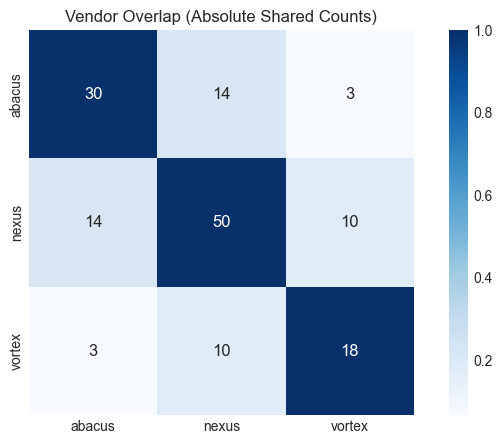

Total Vendors: 74
Total Multi-homing Vendors (Present in >1 market): 21
Multi-homing Vendors (Present in all 3 markets): 3
Vendors active on all 3 markets: ['nethn22', 'sacky', 'safety1st']


In [31]:
# 1. Vendor Jaccard Similarity
j_vendors, c_vendors = utils.calculate_jaccard_with_counts(unique_master, 'Vendor')

# 1a: Vendors
plt.figure(figsize=(20, 5))
plt.subplot(1, 2, 2)
sns.heatmap(j_vendors, annot=c_vendors.values.astype(int), fmt="d", square=True, cmap="Blues", annot_kws={"size" : 12})
plt.title("Vendor Overlap (Absolute Shared Counts)")
plt.show()

vendor_presence = unique_master.groupby('Vendor')['_marketplace'].nunique()

print(f"Total Vendors: {len(vendor_presence)}")
print(f"Total Multi-homing Vendors (Present in >1 market): {sum(vendor_presence > 1)}")
print(f"Multi-homing Vendors (Present in all 3 markets): {sum(vendor_presence == 3)}")

triple_homing = vendor_presence[vendor_presence == 3].index.tolist()
print(f"Vendors active on all 3 markets: {triple_homing}")

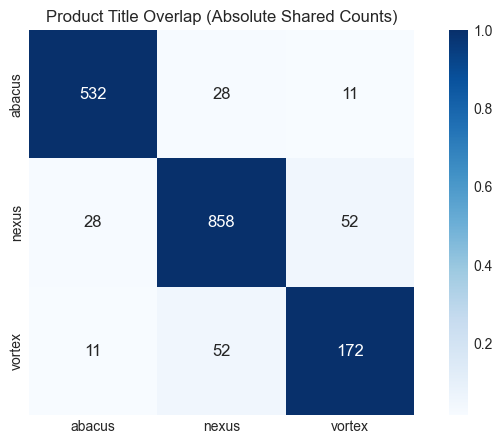

Products present in >1 market: 75
Products present in all 3 markets: 8
Products active on all 3 markets: ['btc-stealer/crypto-clipper', 'metasploit pro', 'quantum builder', 'ridgebot', 'spynote android rat', 'themida crypter - bypass antivirus', 'vshell rat', 'website hacker 2024 - nessus professional']


In [32]:
# 2. Product Jaccard Similarity
j_titles, c_titles = utils.calculate_jaccard_with_counts(unique_master, 'Title')

plt.figure(figsize=(20, 5))
plt.subplot(1, 2, 2)
sns.heatmap(j_titles, annot=c_titles.values.astype(int), fmt="d", square=True, cmap="Blues", annot_kws={"size": 12})
plt.title("Product Title Overlap (Absolute Shared Counts)")
plt.show()

# Normalize Title the same way calculate_jaccard_with_counts does internally
unique_master['Title_norm'] = unique_master['Title'].astype(str).str.strip().str.lower()
product_presence = unique_master.groupby('Title_norm')['_marketplace'].nunique()

print(f"Products present in >1 market: {sum(product_presence > 1)}")
print(f"Products present in all 3 markets: {sum(product_presence == 3)}")

all_presence = product_presence[product_presence == 3].index.tolist()
print(f"Products active on all 3 markets: {all_presence}")

In [33]:
# 5. Directional Arbitrage: is one market systematically pricier?
from scipy.stats import wilcoxon
import itertools

avg_price = master.groupby(['Title','Vendor','_marketplace'])['Price_USD'].mean().reset_index()
pivot = avg_price.pivot_table(index=['Title','Vendor'], columns='_marketplace', values='Price_USD')

markets = ['abacus','nexus','vortex']
for a, b in itertools.combinations(markets, 2):
    paired = pivot[[a,b]].dropna().round(4)
    diff = paired[a] - paired[b].round(4)
    n_total, n_tied = len(paired), (diff==0).sum()
    nonzero = diff[diff!=0]
    if len(nonzero) < 3:
        print(f"{a} vs {b}: n={n_total} ({n_tied} tied), only {len(nonzero)} non-zero pairs — too few to test")
        continue
    stat, p = wilcoxon(paired[a], paired[b])
    print(f"{a} vs {b}: n={n_total} ({n_tied} tied, {len(nonzero)} non-zero), "
          f"mean diff={nonzero.mean():.2f}, W={stat:.1f}, p={p:.4f}")

abacus vs nexus: n=21 (14 tied, 7 non-zero), mean diff=-2.75, W=0.0, p=0.0180
abacus vs vortex: n=9 (8 tied), only 1 non-zero pairs — too few to test
nexus vs vortex: n=47 (28 tied, 19 non-zero), mean diff=1.76, W=38.0, p=0.0218


#### Step 2.4 — Cross-market pricing: same vendor, own currency
Titles are compared only within the same vendor, and prices in the currency the vendor set them in (EUR for Nexus EUR listings and for Abacus listings the platform re-converts; USD otherwise). A vendor-title is *rigid* if one identical price (±1%) is offered on every market where it is listed.

In [34]:
importlib.reload(utils)

# Table 6 (new): titles present on all three markets, split by vendor, own currency
table6_by_vendor = utils.arbitrage_by_vendor(master, presence=3)
display(table6_by_vendor)

# Tables 7 and 8 (new): every vendor-title listed on more than one market
rq4_pairs = utils.cross_market_vendor_titles(master)
rq4_pairs.to_csv('outputs/rq4_cross_market_pairs.csv', index=False)
rigid_col = 'Rigid (same price on every market)'
print(f"Cross-market vendor-titles: {len(rq4_pairs)} from {rq4_pairs['Vendor'].nunique()} vendors")
print(f"Rigid: {rq4_pairs[rigid_col].sum()} ({rq4_pairs[rigid_col].mean()*100:.1f}%)")
no_s1 = rq4_pairs[rq4_pairs['Vendor'] != 'safety1st']
print(f"Rigid without safety1st: {no_s1[rigid_col].sum()} of {len(no_s1)} ({no_s1[rigid_col].mean()*100:.1f}%)")
display(utils.rigidity_by_vendor(rq4_pairs))                      # Table 7
display(rq4_pairs[~rq4_pairs[rigid_col]][['Vendor', 'Title', 'Markets', 'Prices (own currency)']])  # Table 8

# Directional test repeated without safety1st (it supplies almost all non-tied pairs)
from scipy.stats import wilcoxon
m_no_s1 = master[master['Vendor'] != 'safety1st']
pv = m_no_s1.groupby(['Title', 'Vendor', '_marketplace'])['Price_USD'].mean().unstack()
for a, b in [('abacus', 'nexus'), ('abacus', 'vortex'), ('nexus', 'vortex')]:
    p = pv[[a, b]].dropna(); nz = p[(p[a] - p[b]).round(4) != 0]
    print(f"{a} vs {b}: {len(p)} pairs, {len(nz)} non-tied" + (f", W={wilcoxon(p[a], p[b])[0]:.1f}, p={wilcoxon(p[a], p[b])[1]:.4f}" if len(nz) >= 3 else ''))


_marketplace                                           abacus      nexus  \
t                                         Vendor                           
btc-stealer/crypto-clipper                fullzipp   18.0 USD   18.0 USD   
                                          nethn22               18.0 USD   
                                          trio                 44.71 USD   
metasploit pro                            nethn22              499.0 USD   
                                          sacky       4.0 USD    4.0 USD   
quantum builder                           sacky       4.0 USD    4.0 USD   
ridgebot                                  fullzipp   10.0 USD              
                                          sacky      10.0 USD   10.0 USD   
spynote android rat                       aracay                10.0 EUR   
                                          sacky       4.0 USD    4.0 USD   
                                          trio                  20.0 USD   
themida crypter - bypass antivirus        sacky       6.0 USD    6.0 USD   
vshell rat                                sacky       4.0 USD    4.0 USD   
website hacker 2024 - nessus professional safety1st   9.0 EUR   8.99 EUR   

_marketplace                                            vortex  
t                                         Vendor                
btc-stealer/crypto-clipper                fullzipp              
                                          nethn22     28.0 USD  
                                          trio                  
metasploit pro                            nethn22    499.0 USD  
                                          sacky                 
quantum builder                           sacky        4.0 USD  
ridgebot                                  fullzipp              
                                          sacky       10.0 USD  
spynote android rat                       aracay                
                                          sacky        4.0 USD  
                                          trio                  
themida crypter - bypass antivirus        sacky        6.0 USD  
vshell rat                                sacky        4.0 USD  
website hacker 2024 - nessus professional safety1st   9.71 USD

Cross-market vendor-titles: 66 from 8 vendors
Rigid: 42 (63.6%)
Rigid without safety1st: 40 of 45 (88.9%)


,Pairs,Rigid,Switched_EUR_to_USD_on_Nexus,Rigid %
Vendor,,,,
safety1st,21,2,13,9.5
broker01,12,12,0,100.0
sacky,12,12,0,100.0
nethn22,9,6,0,66.7
fullzipp,5,5,0,100.0
heartkidnapper,5,3,0,60.0
hackyboy,1,1,0,100.0
whitechapel,1,1,0,100.0


,Vendor,Title,Markets,Prices (own currency)
19,heartkidnapper,Limitless Keylogger Download,"nexus, vortex",nexus: USD 1.90; vortex: USD 1.99
22,heartkidnapper,Syslogger Download,"nexus, vortex",nexus: USD 1.90; vortex: USD 1.99
26,nethn22,BTC-Stealer/Crypto-Clipper,"nexus, vortex",nexus: USD 18.00; vortex: USD 28.00
27,nethn22,CRACKERS,"nexus, vortex",nexus: USD 10.00; vortex: USD 15.00
31,nethn22,SCMv2.0 - SECURITY & COUNTERATTACK MANAGER,"abacus, nexus",abacus: USD 523.95; nexus: USD 499.00
44,safety1st,10x Monero Silent Miners - Mine XMR (Stealth) ...,"nexus, vortex","nexus: EUR 19.99, USD 21.99; vortex: USD 20.59"
45,safety1st,All About Phishing - Phisher Website Making + ...,"nexus, vortex","nexus: EUR 5.99, USD 5.99; vortex: USD 5.45"
46,safety1st,Bitcoin Wallet Cracker 2024 - Earn Unlimited B...,"nexus, vortex","nexus: EUR 5.99, USD 3.99; vortex: USD 3.24"
47,safety1st,Clone Cards - Card Cloning Software,"nexus, vortex",nexus: EUR 6.99; vortex: USD 3.78
48,safety1st,Clone SIM Cards - Duplicate Sims - Copy SIM Card,"nexus, vortex","nexus: EUR 2.99, USD 3.99; vortex: USD 3.34"


abacus vs nexus: 14 pairs, 0 non-tied
abacus vs vortex: 8 pairs, 0 non-tied
nexus vs vortex: 32 pairs, 4 non-tied, W=1.0, p=0.0782


In [35]:
# 6. Multi-Homing Vendors vs. Vendor Scale
scale_results = utils.test_multihoming_vendor_scale(unique_master)
print(f"Multi-homing vendors:  n={scale_results['multi_n']}, "
      f"median listings={scale_results['multi_median']}, mean={scale_results['multi_mean']:.1f}")
print(f"Single-homing vendors: n={scale_results['single_n']}, "
      f"median listings={scale_results['single_median']}, mean={scale_results['single_mean']:.1f}")
print(f"\nMann-Whitney U (multi > single): U={scale_results['U']:.1f}, p={scale_results['p']:.6f}")

Multi-homing vendors:  n=21, median listings=32.0, mean=41.4
Single-homing vendors: n=53, median listings=5.0, mean=14.0

Mann-Whitney U (multi > single): U=878.0, p=0.000055


## Discussion 4.4: vendor handles also present in Georgoulias et al. (2023a)
Data: `hierarchical_v2.json` downloaded from the authors' Observable notebook (ccrp-hierarchical-edge-bundling), saved in `inputs/`. Handles are matched case-insensitively; a match is a shared name, not a verified identity.

In [37]:
import json
with open("inputs/hierarchical_v2.json", encoding="utf-8") as f:
    g_nodes = json.load(f)
earlier = pd.DataFrame([{'market': n['name'].split('.')[1],
                         'handle': '.'.join(n['name'].split('.')[2:]).strip().lower()} for n in g_nodes])
earlier_markets = earlier.groupby('handle')['market'].agg(lambda s: ', '.join(sorted(set(s))))
earlier_n = earlier.groupby('handle')['market'].nunique()

um = unique_master.copy()
um['handle'] = um['Vendor'].astype(str).str.strip().str.lower()
ours = um.groupby('handle').agg(markets_2025=('_marketplace', lambda s: ', '.join(sorted(set(s)))),
                                unique_products=('Title', 'size'))
ours['multi_homing_2025'] = ours['markets_2025'].str.contains(',')
matched = ours.join(earlier_markets.rename('markets_earlier'), how='inner')
matched['n_markets_earlier'] = earlier_n.reindex(matched.index)

print(f"Handles in this study: {len(ours)} | also in Georgoulias et al. (2023a): {len(matched)} ({len(matched)/len(ours)*100:.1f}%)")
print(f"Multi-homing vendors matched: {matched['multi_homing_2025'].sum()} of {ours['multi_homing_2025'].sum()}; "
      f"single-homing matched: {(~matched['multi_homing_2025']).sum()} of {(~ours['multi_homing_2025']).sum()}")
print(f"Unique products by matched vendors: {matched['unique_products'].sum()} of {len(um)} "
      f"({matched['unique_products'].sum()/len(um)*100:.1f}%)")
print(f"Matched handles on >1 market in the earlier data: {(matched['n_markets_earlier'] > 1).sum()} of {len(matched)} "
      f"(all earlier handles: {(earlier_n > 1).mean()*100:.1f}% of {len(earlier_n)})")
display(matched.sort_values('n_markets_earlier', ascending=False))


Handles in this study: 74 | also in Georgoulias et al. (2023a): 35 (47.3%)
Multi-homing vendors matched: 12 of 21; single-homing matched: 23 of 53
Unique products by matched vendors: 754 of 1609 (46.9%)
Matched handles on >1 market in the earlier data: 27 of 35 (all earlier handles: 20.3% of 858)


,markets_2025,unique_products,multi_homing_2025,markets_earlier,n_markets_earlier
handle,,,,,
g3cko,abacus,15,False,"Alphabay, Cypher, DarkFox, Kingdom, Tor2Door, ...",6
goldapple,nexus,23,False,"Alphabay, DarkFox, Kingdom, Tor2Door, Versus, ...",6
k1to,"abacus, nexus",22,True,"ASAP, Alphabay, Kingdom, Tor2Door, Vice City",5
socialmedia,nexus,11,False,"Alphabay, DarkFox, Kingdom, Tor2Door, Versus",5
rugbykonix,nexus,2,False,"Alphabay, Cypher, DarkFox, Kingdom, Versus",5
rvaska,"abacus, nexus",37,True,"ASAP, Alphabay, DarkFox, Tor2Door, Versus",5
equifax,nexus,1,False,"ASAP, Alphabay, Tor2Door, Versus",4
thedangeroustomato,nexus,35,False,"Alphabay, Cypher, Kingdom, Vice City",4
heartkidnapper,"nexus, vortex",41,True,"ASAP, Alphabay, DarkFox, Tor2Door",4
